# Solving the n-Queens Problem using Local Search

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Helper functions

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""
    
    n = len(board)
    
    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1
    
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])
    
    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')
    
    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## Create a board

Board with 4 conflicts.


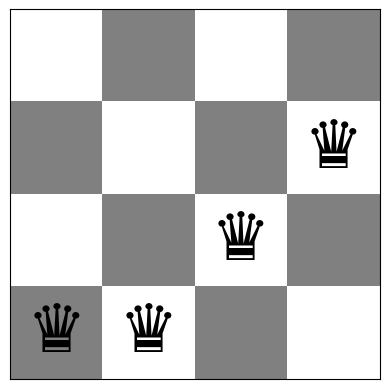

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [3]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


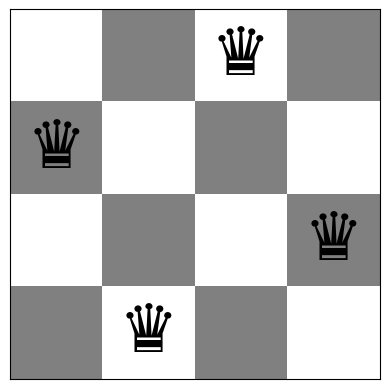

In [4]:
board = [1,3,0,2]
show_board(board)

---
# Bài 2 (Lab 03). Mô hình hóa bài toán n quân hậu

**Phạm vi:** Khảo sát các hàm `random_board(n)`, `show_board(board)`, `conflicts(board)` trong notebook gốc; mô hình hóa trạng thái, sinh lân cận và đối chiếu bài toán 4-Queens, 8-Queens. Phần này bổ sung cho các ví dụ ở trên, **không triển khai sẵn các Task 1–6** của những bài thực hành sau.

## 2.1. Mục tiêu và biểu diễn trạng thái

Bài toán n-Queens yêu cầu đặt `n` quân hậu trên bàn cờ `n × n` để không có hai quân hậu nào tấn công nhau. Mỗi trạng thái được biểu diễn bởi vector `board = [q_0, q_1, ..., q_(n-1)]`, trong đó `q_j` là chỉ số hàng của quân hậu ở cột `j` (đánh số từ 0). Mỗi cột luôn có **đúng một quân hậu** nhưng có thể có nhiều quân cùng hàng hoặc đường chéo, do đó vẫn có xung đột.

- Không gian trạng thái có `n^n` cấu hình: `4^4 = 256` khi n = 4 và `8^8 = 16.777.216` khi n = 8.
- Trạng thái đích: mọi cặp hậu không cùng hàng và không cùng đường chéo.
- Phép dịch chuyển cục bộ: chọn một cột rồi chuyển quân hậu ở cột đó đến **một hàng khác** trong cùng cột.
- Mỗi trạng thái có đúng `n × (n − 1)` láng giềng phân biệt: `12` với n = 4 và `56` với n = 8.

## 2.2. Hàm mục tiêu `conflicts(board)`

Cần cực tiểu hóa `f(board) = conflicts(board)` đến giá trị `0`. Hàm đếm tổng số **cặp** quân hậu tấn công nhau; một cặp có xung đột khi cùng hàng hoặc một trong hai đường chéo. Vì mỗi cột đã có sẵn đúng một quân, không cần xét xung đột cùng cột.

Notebook gốc đếm số quân hậu trên mỗi hàng và hai loại đường chéo, sau đó cộng `C(k, 2) = k(k−1)/2` cho từng hàng/đường chéo chứa `k` quân. Ví dụ, 3 quân cùng hàng tạo ra `C(3, 2) = 3` cặp xung đột; không phải chỉ 1 xung đột.

Ở các phần dưới, hàm `conflicts(board)` và `show_board(board)` **đều được dùng lại nguyên bản** từ cell của giảng viên.

In [5]:
# Bài 2 — Sinh trạng thái ngẫu nhiên có khả năng tái lập.
# random_board() sử dụng bộ sinh số ngẫu nhiên NumPy toàn cục trong notebook gốc.
EX2_SEED = 20261015
np.random.seed(EX2_SEED)

board_4_random = random_board(4)
board_8_random = random_board(8)
board_4_solution = np.asarray([1, 3, 0, 2], dtype=int)

for name, board in [
    ('4-Queens ngẫu nhiên', board_4_random),
    ('4-Queens tham chiếu', board_4_solution),
    ('8-Queens ngẫu nhiên', board_8_random),
]:
    n = len(board)
    assert len(board) == n and all(0 <= int(x) < n for x in board)
    print(f'{name:22s} | board={board.tolist()} | n={n} | f={conflicts(board)}')

assert conflicts(board_4_solution) == 0
print(f'Random seed: {EX2_SEED}')

4-Queens ngẫu nhiên    | board=[3, 0, 3, 1] | n=4 | f=1
4-Queens tham chiếu    | board=[1, 3, 0, 2] | n=4 | f=0
8-Queens ngẫu nhiên    | board=[6, 3, 2, 3, 1, 0, 5, 2] | n=8 | f=7
Random seed: 20261015


### Khảo sát ba hàm có sẵn

- `random_board(n)` sinh mảng NumPy gồm `n` chỉ số hàng, mỗi chỉ số thuộc `[0, n−1]`; một quân hậu được đặt trên mỗi cột.
- `show_board(board)` trực quan hóa bàn cờ và in số cặp xung đột bằng `conflicts(board)`; hàm này **không** tự tối ưu cấu hình.
- `conflicts(board)` trả về số cặp hậu xung đột. Giá trị `0` là điều kiện nghiệm hợp lệ, còn giá trị lớn hơn `0` biểu thị còn ít nhất một cặp xung đột.

Các hình sau cho thấy hai bàn cờ ngẫu nhiên và một lời giải 4-Queens đã biết. Hình vẽ nhằm **khảo sát mô hình trạng thái**, không phải kết quả của thuật toán Hill Climbing.


Bàn cờ 4×4 ngẫu nhiên: [3, 0, 3, 1]
Board with 1 conflicts.


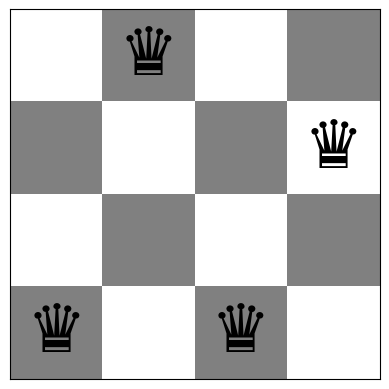


Bàn cờ 4×4 không xung đột [1,3,0,2]: [1, 3, 0, 2]
Board with 0 conflicts.


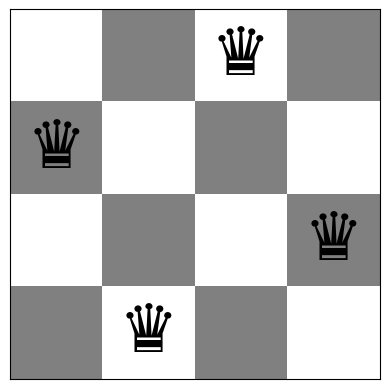


Bàn cờ 8×8 ngẫu nhiên: [6, 3, 2, 3, 1, 0, 5, 2]
Board with 7 conflicts.


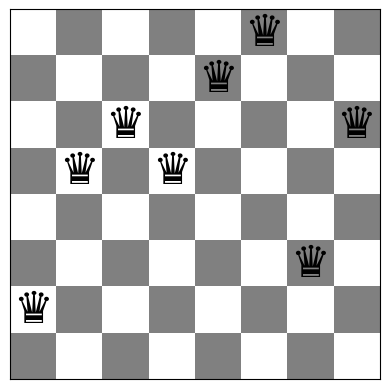

In [6]:
# Trực quan hóa bằng show_board() đã có trong notebook gốc.
for title, board, fs in [
    ('Bàn cờ 4×4 ngẫu nhiên', board_4_random, 48),
    ('Bàn cờ 4×4 không xung đột [1,3,0,2]', board_4_solution, 48),
    ('Bàn cờ 8×8 ngẫu nhiên', board_8_random, 32),
]:
    print(f'\n{title}: {board.tolist()}')
    show_board(board, fontsize=fs)

## 2.3. Trạng thái lân cận và phép di chuyển cục bộ

Với một bàn cờ có `n` cột, mỗi cột có `n−1` lựa chọn hàng mới, nên số lân cận là `n(n−1)`. Để sinh các lân cận, chương trình sao chép vector trạng thái hiện tại, chỉ thay đổi đúng một phần tử `board[column]` sang hàng mới, sau đó giữ các phần tử còn lại. Việc tạo bản sao bảo đảm **không làm biến đổi bàn cờ gốc** trong khi đánh giá các lựa chọn.

Hàm `local_neighbors(board)` dưới đây chỉ dùng để *mô hình hóa và kiểm chứng không gian lân cận*. Nó không chọn bước tốt hơn, nên chưa phải thuật toán Hill Climbing.

In [7]:
def local_neighbors(board):
    """Trả về (cột được chọn, hàng mới, bàn cờ mới) cho mọi bước hợp lệ."""
    current = np.asarray(board, dtype=int)
    n = len(current)
    neighbors = []
    for column in range(n):
        for new_row in range(n):
            if new_row == current[column]:
                continue  # Không tính thao tác đứng yên là một lân cận.
            moved = current.copy()
            moved[column] = new_row
            neighbors.append((column, new_row, moved))
    return neighbors

for name, board in [
    ('4-Queens ngẫu nhiên', board_4_random),
    ('4-Queens tham chiếu', board_4_solution),
    ('8-Queens ngẫu nhiên', board_8_random),
]:
    n = len(board)
    neighbors = local_neighbors(board)
    unique_boards = {tuple(x[2]) for x in neighbors}
    assert len(neighbors) == len(unique_boards) == n * (n - 1)
    assert all(np.count_nonzero(new_board != board) == 1
               for _, _, new_board in neighbors)
    print(f'{name:22s}: {len(neighbors)} láng giềng; '
          f'công thức n(n-1) = {n}×{n-1} = {n * (n - 1)}')

print('Ví dụ 5 lân cận đầu tiên của board 4-Queens ngẫu nhiên:')
for col, row, new_board in local_neighbors(board_4_random)[:5]:
    print(f'  cột={col}, hàng mới={row}: {new_board.tolist()}, '
          f'f={conflicts(new_board)}')

4-Queens ngẫu nhiên   : 12 láng giềng; công thức n(n-1) = 4×3 = 12
4-Queens tham chiếu   : 12 láng giềng; công thức n(n-1) = 4×3 = 12
8-Queens ngẫu nhiên   : 56 láng giềng; công thức n(n-1) = 8×7 = 56
Ví dụ 5 lân cận đầu tiên của board 4-Queens ngẫu nhiên:
  cột=0, hàng mới=0: [0, 0, 3, 1], f=1
  cột=0, hàng mới=1: [1, 0, 3, 1], f=3
  cột=0, hàng mới=2: [2, 0, 3, 1], f=0
  cột=1, hàng mới=1: [3, 1, 3, 1], f=2
  cột=1, hàng mới=2: [3, 2, 3, 1], f=3


## 2.4. Thực nghiệm n = 4 và n = 8

Ở đây ta so sánh: (1) bàn cờ 4-Queens ngẫu nhiên, (2) cấu hình tham chiếu `[1,3,0,2]`, (3) bàn cờ 8-Queens ngẫu nhiên. Ngoài giá trị `f(board)`, mã còn thống kê phân bố giá trị xung đột trong **toàn bộ lân cận một bước**. Bảng này giúp chuẩn bị cho việc chọn bước cải thiện trong các Task 1–3 về Hill Climbing.

Các phép đo sử dụng một seed cố định; kết quả cụ thể của bàn cờ ngẫu nhiên có thể khác nếu bạn đổi seed hoặc phiên bản trình tạo số ngẫu nhiên.

In [8]:
# Kiểm chứng độc lập cách đếm số cặp hậu tấn công nhau.
def conflicts_pairwise(board):
    board = np.asarray(board, dtype=int)
    n = len(board)
    return sum(
        board[i] == board[j] or abs(int(board[i]) - int(board[j])) == j - i
        for i in range(n) for j in range(i + 1, n)
    )

boards_to_compare = [
    ('4-Queens ngẫu nhiên', board_4_random),
    ('4-Queens tham chiếu', board_4_solution),
    ('8-Queens ngẫu nhiên', board_8_random),
]
results_bai2 = []
for name, board in boards_to_compare:
    n = len(board)
    neighbor_conflicts = [conflicts(new_board)
                          for _, _, new_board in local_neighbors(board)]
    current_f = conflicts(board)
    assert current_f == conflicts_pairwise(board)
    result = {
        'case': name, 'n': n, 'state': str(board.tolist()),
        'conflicts': current_f,
        'n_neighbors': len(neighbor_conflicts),
        'min_neighbor_conflicts': min(neighbor_conflicts),
        'improving_neighbors': sum(v < current_f for v in neighbor_conflicts),
        'zero_conflict_neighbors': sum(v == 0 for v in neighbor_conflicts),
    }
    results_bai2.append(result)

print(f'{"Thí nghiệm":23s} {"n":>2s} {"f":>4s} {"Láng giềng":>11s} '
      f'{"f nhỏ nhất":>12s} {"Cải thiện":>10s} {"f=0":>6s}')
for row in results_bai2:
    print(f'{row["case"]:23s} {row["n"]:2d} {row["conflicts"]:4d} '
          f'{row["n_neighbors"]:11d} {row["min_neighbor_conflicts"]:12d} '
          f'{row["improving_neighbors"]:10d} {row["zero_conflict_neighbors"]:6d}')

assert conflicts(board_4_solution) == 0
assert len(local_neighbors(board_4_random)) == 12
assert len(local_neighbors(board_8_random)) == 56
print('Kiểm thử: PASS (xung đột, kích thước lân cận, lời giải mẫu).')

Thí nghiệm               n    f  Láng giềng   f nhỏ nhất  Cải thiện    f=0
4-Queens ngẫu nhiên      4    1          12            0          1      1
4-Queens tham chiếu      4    0          12            1          0      0
8-Queens ngẫu nhiên      8    7          56            4         17      0
Kiểm thử: PASS (xung đột, kích thước lân cận, lời giải mẫu).


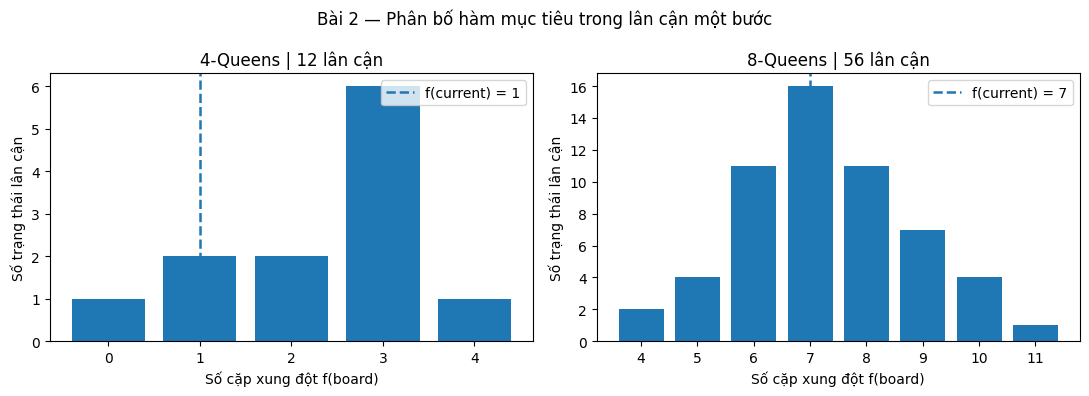

In [9]:
# Vẽ phân bố số xung đột ở các lân cận của 4-Queens và 8-Queens.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.0))
for ax, n, board in zip(axes, [4, 8], [board_4_random, board_8_random]):
    vals = [conflicts(state) for _, _, state in local_neighbors(board)]
    xvalues = np.arange(min(vals), max(vals) + 1)
    counts = [vals.count(int(k)) for k in xvalues]
    ax.bar(xvalues, counts)
    ax.axvline(conflicts(board), linestyle='--', linewidth=1.8,
               label=f'f(current) = {conflicts(board)}')
    ax.set_title(f'{n}-Queens | {len(vals)} lân cận')
    ax.set_xlabel('Số cặp xung đột f(board)')
    ax.set_ylabel('Số trạng thái lân cận')
    ax.set_xticks(xvalues)
    ax.legend()
fig.suptitle('Bài 2 — Phân bố hàm mục tiêu trong lân cận một bước')
fig.tight_layout()
plt.show()

## 2.5. Nhận xét và kết luận

Với seed **20261015**, `random_board(4)` tạo `[3,0,3,1]` có `f=1`, còn cấu hình tham chiếu `[1,3,0,2]` có `f=0`, do không có hai quân hậu nào cùng hàng hoặc đường chéo. `random_board(8)` tạo `[6,3,2,3,1,0,5,2]` với `f=7`. Giá trị `f` trong các ví dụ này đã được đối chiếu bằng một phép đếm cặp quân hậu độc lập.

- Khi **n=4**, mỗi bàn cờ có `4×3=12` lân cận. Bàn cờ ngẫu nhiên có 1 lân cận cải thiện được `f` xuống 0. Tại `[1,3,0,2]`, mọi phép chuyển một quân hậu sang hàng khác đều làm phát sinh xung đột, vì vậy không có lân cận nào cải thiện so với `f=0`.
- Khi **n=8**, số lân cận tăng thành `8×7=56`. Trong thí nghiệm này, bàn cờ ngẫu nhiên có 17 lân cận giảm `f` so với trạng thái hiện tại, nhưng không có lân cận nào đạt ngay `f=0`.

Biểu diễn một quân hậu trên mỗi cột loại bỏ hoàn toàn các xung đột theo cột và làm trạng thái gọn hơn so với việc xét mọi cách chọn `n` ô bất kỳ trên bàn cờ. Hàm `conflicts(board)` định lượng chất lượng trạng thái, còn toán tử chuyển một quân hậu sang hàng khác xác định cấu trúc lân cận cho các thuật toán tìm kiếm cục bộ ở những bài tiếp theo.

**Giới hạn phạm vi:** Bài 2 chỉ mô hình hóa, sinh lân cận và đánh giá hàm mục tiêu. Nó không chứng minh rằng Hill Climbing hoặc phương pháp nào khác chắc chắn tìm được nghiệm; những thuật toán đó sẽ được triển khai ở Bài 3 và Bài 4.

### Các kết quả cần nhớ

| Nội dung | n = 4 | n = 8 |
|---|---:|---:|
| Số trạng thái theo biểu diễn vector | 256 | 16.777.216 |
| Số lân cận một bước | 12 | 56 |
| Mục tiêu | `f(board)=0` | `f(board)=0` |

Toàn bộ các Task 1–6 trong notebook gốc được giữ nguyên để tiếp tục ở các bài thực hành sau.

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 

In [10]:
# TASK 1: Steepest-ascent Hill Climbing
# Kiểm tra tất cả n(n-1) lân cận, chọn f nhỏ nhất, chỉ đi khi f giảm.
import time

def steepest_ascent(board, max_steps=1000):
    """Minimize conflicts; return solution + strictly measured statistics.

    evaluations includes evaluation of initial board and each tested neighbor.
    iterations counts accepted moves. Never mutates input board.
    """
    current = np.asarray(board, dtype=int).copy()
    initial = current.copy()
    evaluations = 0

    def eval_f(state):
        nonlocal evaluations
        evaluations += 1
        return int(conflicts(state))

    t0 = time.perf_counter()
    current_f = eval_f(current)
    initial_f = current_f
    history = [current_f]
    steps = 0
    status = 'SOLVED' if current_f == 0 else 'LOCAL_MINIMUM'

    while current_f > 0 and steps < max_steps:
        best_f = current_f
        best_board = None
        for _, _, candidate in local_neighbors(current):
            candidate_f = eval_f(candidate)
            if candidate_f < best_f:
                best_f = candidate_f
                best_board = candidate
        if best_board is None:
            status = 'LOCAL_MINIMUM'
            break
        current = best_board
        current_f = best_f
        steps += 1
        history.append(current_f)
        status = 'SOLVED' if current_f == 0 else 'LOCAL_MINIMUM'

    if current_f != 0 and steps == max_steps:
        status = 'STEP_LIMIT'

    return {
        'algorithm': 'Steepest-ascent', 'initial_board': initial,
        'board': current, 'initial_f': initial_f, 'final_f': current_f,
        'steps': steps, 'evaluations': evaluations,
        'samples': evaluations - 1, 'history': history, 'status': status,
        'success': current_f == 0,
        'elapsed_ms': (time.perf_counter() - t0) * 1000.0
    }


### Giải thích Task 1 – Steepest-ascent

Tại mỗi bước, thuật toán sinh và đánh giá **toàn bộ** `n(n−1)` lân cận bằng `local_neighbors(board)` và `conflicts(board)`, chọn một trạng thái có số cặp xung đột nhỏ nhất. Chỉ chấp nhận bước di chuyển khi `f(new) < f(current)`; nếu không còn lân cận cải thiện, dừng tại một cực tiểu cục bộ. Nếu có nhiều ứng viên cùng mức tốt nhất, phiên bản này lấy ứng viên đầu tiên theo thứ tự sinh lân cận. Trạng thái đầu vào không bị sửa đổi.

## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

In [11]:
# TASK 2: Inefficient Stochastic Hill Climbing
# Mỗi lượt: xét tất cả lân cận, lưu tất cả nước đi làm giảm conflicts,
# rồi lấy ngẫu nhiên một nước đi cải thiện (không nhất thiết là nước tốt nhất).
def stochastic_all_improvements(board, seed=0, max_steps=1000):
    current = np.asarray(board, dtype=int).copy()
    initial = current.copy()
    rng = np.random.default_rng(seed)
    evaluations = 0

    def eval_f(state):
        nonlocal evaluations
        evaluations += 1
        return int(conflicts(state))

    t0 = time.perf_counter()
    current_f = eval_f(current)
    initial_f = current_f
    history = [current_f]
    steps = 0
    status = 'SOLVED' if current_f == 0 else 'LOCAL_MINIMUM'

    while current_f > 0 and steps < max_steps:
        improving = []
        for _, _, candidate in local_neighbors(current):
            candidate_f = eval_f(candidate)
            if candidate_f < current_f:
                improving.append((candidate, candidate_f))
        if not improving:
            status = 'LOCAL_MINIMUM'
            break
        j = int(rng.integers(len(improving)))
        current, current_f = improving[j]
        steps += 1
        history.append(current_f)
        status = 'SOLVED' if current_f == 0 else 'LOCAL_MINIMUM'

    if current_f != 0 and steps == max_steps:
        status = 'STEP_LIMIT'

    return {
        'algorithm': 'Stochastic (all)', 'initial_board': initial,
        'board': current, 'initial_f': initial_f, 'final_f': current_f,
        'steps': steps, 'evaluations': evaluations,
        'samples': evaluations - 1, 'history': history, 'status': status,
        'success': current_f == 0,
        'elapsed_ms': (time.perf_counter() - t0) * 1000.0
    }


### Giải thích Task 2 – Inefficient Stochastic

Tương tự Steepest-ascent, mỗi lượt vẫn tính `conflicts()` cho tất cả `n(n−1)` lân cận. Tuy nhiên, thay vì lấy lân cận tốt nhất, thuật toán lấy **ngẫu nhiên một lân cận có `f` nhỏ hơn `f` hiện tại**. Seed cố định đảm bảo việc chọn ngẫu nhiên có thể tái lập. Nếu không còn bước cải thiện, thuật toán dừng ở cực tiểu cục bộ. Cách làm này tốn công quét toàn bộ các lân cận tại mỗi bước.

__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way: 

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state. 
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__ 

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

In [12]:
# TASK 3: Efficient Stochastic / First-choice Hill Climbing
# Sinh từng láng giềng ngẫu nhiên (có hoàn lại). Chấp nhận ngay nếu f giảm.
# Sau k thử liên tiếp không cải thiện, dừng với trạng thái TRY_LIMIT,
# không khẳng định chắc chắn đã đạt local minimum.
import math

def default_no_improvement_limit(n, miss_prob=0.05):
    """k≈M ln(1/p): xác suất bỏ sót *một* move chỉ định ≤p.

    M=n(n-1) local moves, sampled uniformly with replacement.
    Equivalent: expected coverage ≥ 1-p, not guaranteed full coverage.
    """
    M = n * (n - 1)
    return max(1, int(math.ceil(M * math.log(1.0 / miss_prob))))


def first_choice_hill_climbing(board, seed=0, max_steps=1000,
                               max_no_improvement=None):
    current = np.asarray(board, dtype=int).copy()
    initial = current.copy()
    n = len(current)
    rng = np.random.default_rng(seed)
    evaluations = 0

    if max_no_improvement is None:
        max_no_improvement = default_no_improvement_limit(n)
    if max_no_improvement <= 0:
        raise ValueError('max_no_improvement must be positive')

    def eval_f(state):
        nonlocal evaluations
        evaluations += 1
        return int(conflicts(state))

    t0 = time.perf_counter()
    current_f = eval_f(current)
    initial_f = current_f
    history = [current_f]
    steps = 0
    attempted = 0
    failures = 0
    status = 'SOLVED' if current_f == 0 else 'TRY_LIMIT'

    while current_f > 0 and steps < max_steps and failures < max_no_improvement:
        column = int(rng.integers(n))
        # Uniform random alternative row, excluding the current row.
        old_row = int(current[column])
        alternative = int(rng.integers(n - 1))
        new_row = alternative if alternative < old_row else alternative + 1
        candidate = current.copy()
        candidate[column] = new_row
        candidate_f = eval_f(candidate)
        attempted += 1
        if candidate_f < current_f:
            current = candidate
            current_f = candidate_f
            steps += 1
            failures = 0
            history.append(current_f)
            status = 'SOLVED' if current_f == 0 else 'TRY_LIMIT'
        else:
            failures += 1

    if current_f == 0:
        status = 'SOLVED'
    elif steps == max_steps:
        status = 'STEP_LIMIT'
    else:
        status = 'TRY_LIMIT'

    return {
        'algorithm': 'First-choice', 'initial_board': initial,
        'board': current, 'initial_f': initial_f, 'final_f': current_f,
        'steps': steps, 'evaluations': evaluations,
        'samples': attempted, 'history': history, 'status': status,
        'success': current_f == 0, 'max_no_improvement': max_no_improvement,
        'elapsed_ms': (time.perf_counter() - t0) * 1000.0
    }


### Giải thích Task 3 – Efficient Stochastic / First-choice

Mỗi lần thử thuật toán chỉ sinh một lân cận ngẫu nhiên và đánh giá `conflicts()` đúng một lần; nếu `f` giảm thì chấp nhận ngay và đặt lại số lần không cải thiện về 0. Khác với Task 1–2, cách này không biết chắc có còn lân cận tốt hay không.

Gọi `M=n(n−1)` là số phép di chuyển hợp lệ. Khi thử ngẫu nhiên *có hoàn lại*, xác suất **chưa từng chọn một phép di chuyển cố định** sau `k` lần là `(1−1/M)^k ≤ exp(−k/M)`. Chọn `k=ceil(M×ln(1/0.05))` khiến xác suất bỏ sót một phép di chuyển cụ thể không quá 5%; tỷ lệ số phép di chuyển phân biệt được thử đạt ít nhất khoảng 95% theo kỳ vọng. Đây **không phải bảo đảm đã thử toàn bộ lân cận**, nên dùng trạng thái dừng `TRY_LIMIT` thay vì khẳng định `LOCAL_MINIMUM`.

Ở `n=4`, `M=12`, ngưỡng mặc định là 36 lần thử liên tục không cải thiện; ở `n=8`, `M=56`, ngưỡng là 168. Các bước cải thiện làm giảm số xung đột nghiêm ngặt, do đó không tạo vòng lặp tăng/giữ nguyên `f`.

---
## Bài 3 – Thực nghiệm và đánh giá Task 1–3

Tiến hành chạy ba thuật toán với cùng bàn cờ ban đầu để so sánh công bằng. Các chỉ số:

- `steps`: số lần **chấp nhận** chuyển trạng thái làm giảm hàm mục tiêu.
- `evaluations`: số lần **thực sự gọi** `conflicts()`, kể cả lần đánh giá trạng thái bắt đầu.
- `final_f`: số cặp quân hậu xung đột khi kết thúc.
- `elapsed_ms`: thời gian chạy đo bằng `time.perf_counter()` trong một lượt. Thời gian đơn lẻ chịu dao động hệ thống, nên cần đối chiếu thêm các thống kê trung bình/median.
- `SOLVED`: đạt `f=0`; `LOCAL_MINIMUM`: đã kiểm tra toàn bộ lân cận nhưng không còn bước cải thiện; `TRY_LIMIT`: hết ngân sách lấy mẫu, **chưa chắc** là local minimum.


In [13]:
# Thực nghiệm một lần trên đúng hai bàn cờ từ Bài 2.
import pandas as pd

ALGOS_BAI3 = [
    ('Steepest-ascent', lambda board, seed: steepest_ascent(board)),
    ('Stochastic (all)', lambda board, seed: stochastic_all_improvements(board, seed=seed)),
    ('First-choice', lambda board, seed: first_choice_hill_climbing(board, seed=seed)),
]

def result_row(result, n, case, seed):
    return {
        'n': n, 'case': case, 'algorithm': result['algorithm'],
        'seed': seed, 'initial_f': result['initial_f'],
        'final_f': result['final_f'], 'steps': result['steps'],
        'evaluations': result['evaluations'], 'elapsed_ms': result['elapsed_ms'],
        'status': result['status'], 'success': result['success'],
        'initial_board': str(result['initial_board'].tolist()),
        'final_board': str(result['board'].tolist())
    }

DEMO_SEED = 20261015
DEMO_CASES = [('4-Queens random', board_4_random),
              ('8-Queens random', board_8_random)]
rows_demo=[]
demo_results={}
for case_name, start in DEMO_CASES:
    print(f'\n{case_name}: initial={start.tolist()}, f={conflicts(start)}')
    for name, run in ALGOS_BAI3:
        result = run(start, DEMO_SEED)
        assert conflicts(result['board']) == result['final_f']
        assert np.array_equal(result['initial_board'], start)
        assert all(a > b for a,b in zip(result['history'], result['history'][1:]))
        rows_demo.append(result_row(result,len(start),case_name,DEMO_SEED))
        demo_results[(case_name,name)] = result
        print(f'  {name:19s}: f={result["final_f"]}, '
              f'steps={result["steps"]}, evals={result["evaluations"]}, '
              f'status={result["status"]}')

df_demo_bai3 = pd.DataFrame(rows_demo)
display(df_demo_bai3[['n','case','algorithm','initial_f','final_f','steps','evaluations','elapsed_ms','status']].round(3))


4-Queens random: initial=[3, 0, 3, 1], f=1
  Steepest-ascent    : f=0, steps=1, evals=13, status=SOLVED
  Stochastic (all)   : f=0, steps=1, evals=13, status=SOLVED
  First-choice       : f=0, steps=1, evals=11, status=SOLVED

8-Queens random: initial=[6, 3, 2, 3, 1, 0, 5, 2], f=7
  Steepest-ascent    : f=1, steps=3, evals=225, status=LOCAL_MINIMUM
  Stochastic (all)   : f=1, steps=6, evals=393, status=LOCAL_MINIMUM
  First-choice       : f=1, steps=5, evals=226, status=TRY_LIMIT


,n,case,algorithm,initial_f,final_f,steps,evaluations,elapsed_ms,status
0,4,4-Queens random,Steepest-ascent,1,0,1,13,0.071,SOLVED
1,4,4-Queens random,Stochastic (all),1,0,1,13,0.074,SOLVED
2,4,4-Queens random,First-choice,1,0,1,11,0.072,SOLVED
3,8,8-Queens random,Steepest-ascent,7,1,3,225,1.432,LOCAL_MINIMUM
4,8,8-Queens random,Stochastic (all),7,1,6,393,2.259,LOCAL_MINIMUM
5,8,8-Queens random,First-choice,7,1,5,226,2.124,TRY_LIMIT


### Kiểm chứng đặc tả thuật toán

Bên cạnh kết quả một lần chạy, kiểm chứng: (1) `f` giảm nghiêm ngặt trên mỗi bước được chấp nhận; (2) không làm thay đổi đầu vào; (3) nghiệm cuối được xác nhận bằng `conflicts()`; (4) Task 1–2 đánh giá toàn bộ `n(n−1)` láng giềng ở mỗi lượt; và (5) với First-choice, số lần gọi hàm mục tiêu bằng `1 + số lần thử lấy mẫu`. Bàn cờ tham chiếu `[1,3,0,2]` phải dừng ngay với `f=0`, không phát sinh bước tìm kiếm.

In [14]:
# Các kiểm tra xác nhận tính đúng đắn.
for n in [4, 8]:
    M = n*(n-1)
    x = default_no_improvement_limit(n)
    assert x == int(math.ceil(M*math.log(20)))
    test_board = np.arange(n, dtype=int) % n
    original = test_board.copy()
    for _, fn in ALGOS_BAI3:
        r = fn(test_board, 123)
        assert np.array_equal(test_board, original), 'Input mutated'
        assert r['evaluations'] >= 1 and r['steps'] == len(r['history'])-1
        assert all(a>b for a,b in zip(r['history'],r['history'][1:]))
        if r['algorithm'] != 'First-choice':
            assert (r['evaluations']-1) % M == 0
        else:
            assert r['evaluations'] == 1 + r['samples']
        if r['status'] == 'LOCAL_MINIMUM':
            assert not any(conflicts(nb)<r['final_f'] for _,_,nb in local_neighbors(r['board']))
        if r['success']:
            assert r['final_f'] == 0
    print(f'n={n}: M={M} láng giềng, ngưỡng không cải thiện={x}, kiểm thử đạt')

known = np.array([1,3,0,2])
for _, fn in ALGOS_BAI3:
    r=fn(known, 123)
    assert r['final_f']==0 and r['steps']==0 and r['evaluations']==1
print('Đã xác nhận cấu hình [1,3,0,2] dừng ngay tại nghiệm tối ưu.')

n=4: M=12 láng giềng, ngưỡng không cải thiện=36, kiểm thử đạt
n=8: M=56 láng giềng, ngưỡng không cải thiện=168, kiểm thử đạt
Đã xác nhận cấu hình [1,3,0,2] dừng ngay tại nghiệm tối ưu.


### Thực nghiệm nhiều lần trên cùng điều kiện

Để giảm ảnh hưởng của ngẫu nhiên, thử mỗi phương pháp trên 20 bàn cờ khởi tạo độc lập cho mỗi `n=4,8`. Ba thuật toán cùng dùng **chính xác một bàn cờ ban đầu** ở từng lượt; các quyết định ngẫu nhiên được sinh bởi `np.random.default_rng(seed)` độc lập, không làm nhiễu bộ sinh ngẫu nhiên toàn cục. Thống kê số bước, lần đánh giá hàm mục tiêu, chi phí kết quả và thời gian trung bình, kèm tỉ lệ đạt nghiệm `f=0`. Đối với thời gian chạy, các số đo chỉ mang tính tham khảo vì nhiễu hệ thống.

In [15]:
# Thực nghiệm nhiều lần – vừa đủ phục vụ Bài 3;
# Bài 8/Task 6 sẽ thực hiện khảo sát >=100 lần theo yêu cầu gốc.
N_TRIALS_BAI3 = 20
rows_benchmark=[]
for n in (4, 8):
    for trial in range(N_TRIALS_BAI3):
        seed = 20261015 + 1000*n + trial
        rng = np.random.default_rng(seed)
        start = rng.integers(0,n,size=n)
        for name, runner in ALGOS_BAI3:
            r = runner(start, seed=seed)
            rows_benchmark.append(result_row(r,n,f'trial_{trial+1:02d}',seed))

df_benchmark_bai3 = pd.DataFrame(rows_benchmark)
summary_bai3=(df_benchmark_bai3.groupby(['n','algorithm'],sort=False)
    .agg(trials=('success','size'), success_rate=('success','mean'),
         avg_final_f=('final_f','mean'), avg_steps=('steps','mean'),
         avg_evaluations=('evaluations','mean'),
         median_evaluations=('evaluations','median'),
         avg_time_ms=('elapsed_ms','mean'), median_time_ms=('elapsed_ms','median'))
    .reset_index())
print('Kết quả thống kê trên cùng bàn cờ khởi tạo mỗi trial:')
display(summary_bai3.round(3))

df_demo_bai3.to_csv('Bai3_Demo_Results.csv',index=False)
df_benchmark_bai3.to_csv('Bai3_Trial_Results.csv',index=False)
summary_bai3.to_csv('Bai3_Summary_Results.csv',index=False)
print('Đã lưu 3 file CSV vào thư mục đang chạy notebook.')

Kết quả thống kê trên cùng bàn cờ khởi tạo mỗi trial:


,n,algorithm,trials,success_rate,avg_final_f,avg_steps,avg_evaluations,median_evaluations,avg_time_ms,median_time_ms
0,4,Steepest-ascent,20,0.55,0.45,1.65,26.20,25.0,0.122,0.101
1,4,Stochastic (all),20,0.50,0.50,1.85,29.20,25.0,0.125,0.097
2,4,First-choice,20,0.25,0.80,1.90,37.05,42.0,0.229,0.256
3,8,Steepest-ascent,20,0.25,1.30,3.05,213.80,225.0,1.410,1.393
4,8,Stochastic (all),20,0.10,1.55,4.20,286.60,281.0,1.894,1.897
5,8,First-choice,20,0.20,1.15,4.85,197.80,210.0,1.993,1.846


Đã lưu 3 file CSV vào thư mục đang chạy notebook.


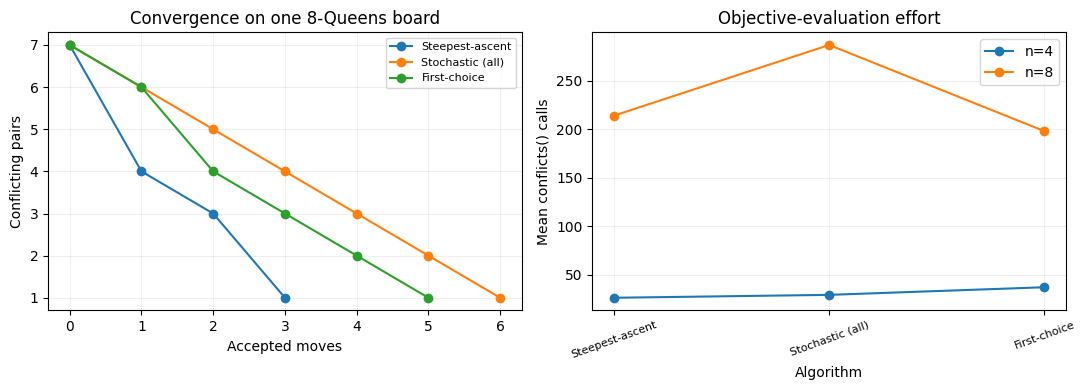

In [16]:
# Đồ thị hội tụ đại diện trên n=8 và so sánh công sức đánh giá.
from pathlib import Path

fig,axes = plt.subplots(1,2,figsize=(11,4.0))
case='8-Queens random'
for algo,_ in ALGOS_BAI3:
    r = demo_results[(case,algo)]
    axes[0].plot(range(len(r['history'])),r['history'],marker='o',label=algo)
axes[0].set(xlabel='Accepted moves',ylabel='Conflicting pairs',
            title='Convergence on one 8-Queens board')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=.2)

for n in (4,8):
    part = summary_bai3[summary_bai3['n']==n]
    axes[1].plot(part['algorithm'],part['avg_evaluations'],marker='o',label=f'n={n}')
axes[1].set(xlabel='Algorithm',ylabel='Mean conflicts() calls',
            title='Objective-evaluation effort')
axes[1].tick_params(axis='x',rotation=20,labelsize=8)
axes[1].legend()
axes[1].grid(alpha=.2)
fig.tight_layout()
Path('Images').mkdir(exist_ok=True)
fig.savefig('Images/Bai3_HillClimbing_Comparison.png',dpi=170,bbox_inches='tight')
plt.show()

### Nhận xét và kết luận Bài 3

- Steepest-ascent chọn lân cận có giá trị `f` thấp nhất sau khi đánh giá toàn bộ `n(n−1)` nước đi. Vì chỉ nhận bước cải thiện nghiêm ngặt, thuật toán có thể dừng tại một cực tiểu cục bộ khác `0`.
- Inefficient Stochastic cũng phải quét toàn bộ lân cận mỗi lượt nhưng chọn ngẫu nhiên giữa các lân cận cải thiện. Vì vậy, đường hội tụ và nghiệm cuối có thể khác Steepest-ascent, trong khi chi phí đánh giá lân cận theo mỗi vòng cải thiện vẫn cao.
- Efficient Stochastic / First-choice có thể chấp nhận sớm một bước cải thiện mà không quét toàn bộ lân cận. Tuy nhiên, khi đã khó cải thiện, thuật toán có thể dành nhiều lần thử ngẫu nhiên trước khi dừng tại `TRY_LIMIT`; không mặc nhiên khẳng định nhanh hơn trong mọi lần chạy. Chi phí tìm kiếm phụ thuộc vào mật độ lân cận cải thiện và ngưỡng số lần thử.
- Các giá trị trong bảng là phép đo thực nghiệm, phụ thuộc seed và số lượt chạy. Task 6 ở Bài 8 sẽ khảo sát mẫu lớn hơn (ít nhất 100 lượt) cùng các thuật toán Random Restart và Simulated Annealing để so sánh toàn diện.

**Kết luận:** Ba thuật toán đều làm giảm số cặp xung đột nhưng khác nhau ở chiến lược lựa chọn lân cận và số lần đánh giá hàm mục tiêu. Không thuật toán nào trong ba phương pháp bảo đảm đạt `f=0` từ mọi trạng thái khởi tạo vì có thể mắc kẹt ở cực tiểu cục bộ.

## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

Trong Bài 4, tối đa 100 lần chạy độc lập (bao gồm lượt đầu); số lần **restart** bằng số lượt đã chạy trừ một. Mỗi lượt khởi đầu từ một bàn cờ ngẫu nhiên và sử dụng một thuật toán của Task 1–3.

In [17]:
# TASK 4 – Random Restart cho ba biến thể Hill Climbing (Bài 3).
# Cùng một seed + initial_board => cùng chuỗi bàn cờ khởi tạo giữa ba biến thể.
# max_starts=100 gồm cả lần chạy đầu tiên (tối đa 99 lần restart).
def random_restart_hill_climbing(initial_board, algorithm='steepest',
                                 seed=0, max_starts=100, max_steps=1000):
    if not (1 <= max_starts <= 100):
        raise ValueError('max_starts must be in [1, 100]')
    choices = {
        'steepest': steepest_ascent,
        'stochastic_all': stochastic_all_improvements,
        'first_choice': first_choice_hill_climbing,
    }
    if algorithm not in choices:
        raise ValueError(f'unknown algorithm: {algorithm}')
    initial = np.asarray(initial_board, dtype=int).copy()
    n = len(initial)
    rng = np.random.default_rng(seed)
    solver = choices[algorithm]
    best_f = float('inf')
    best_board = None
    history_best = []
    evaluations = 0
    total_steps = 0
    runs = 0
    t0 = time.perf_counter()

    for attempt in range(max_starts):
        # Giữ nguyên cùng trạng thái đầu ở lượt 1, các lần sau khởi tạo ngẫu nhiên.
        start = initial.copy() if attempt == 0 else rng.integers(0, n, size=n)
        solver_seed = seed + 100_000 + attempt
        if algorithm == 'steepest':
            res = solver(start, max_steps=max_steps)
        else:
            res = solver(start, seed=solver_seed, max_steps=max_steps)
        runs += 1
        evaluations += res['evaluations']
        total_steps += res['steps']
        if res['final_f'] < best_f:
            best_f = int(res['final_f'])
            best_board = res['board'].copy()
        history_best.append(int(best_f))
        if best_f == 0:
            break

    return {
        'algorithm': f'Random Restart / {algorithm}',
        'initial_board': initial, 'board': best_board,
        'initial_f': int(conflicts(initial)),
        'final_f': int(best_f), 'best_f': int(best_f),
        'runs': runs, 'restarts_used': runs-1,
        'steps': total_steps, 'evaluations': evaluations,
        'history_best': history_best,
        'success': best_f == 0,
        'status': 'SOLVED' if best_f == 0 else 'RESTART_LIMIT',
        'elapsed_ms': (time.perf_counter()-t0)*1000.0,
    }


## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

Bài thực hành dùng lịch nhiệt hàm mũ T(t) = T0 × alpha^t với 0 < alpha < 1. Khi Δ = 0, trạng thái mới được chấp nhận như một bước không xấu hơn; khi Δ > 0, xác suất chấp nhận là exp(−Δ/T). Phải giữ lại **best_board** vì trạng thái cuối có thể kém hơn trạng thái tốt nhất từng gặp.

In [18]:
# TASK 5 – Simulated Annealing với lịch nhiệt hàm mũ.
# max_iter: số lần sinh/đánh giá tối đa một lân cận.
# Để tái lập, mọi lựa chọn ngẫu nhiên đều dùng default_rng(seed).
def simulated_annealing_queens(initial_board, seed=0, T0=3.0, alpha=0.995,
                               max_iter=2500):
    if T0 <= 0 or not (0 < alpha < 1) or max_iter < 0:
        raise ValueError('Require T0>0, 0<alpha<1 and max_iter>=0')
    initial = np.asarray(initial_board, dtype=int).copy()
    n = len(initial)
    rng = np.random.default_rng(seed)
    t0 = time.perf_counter()
    current = initial.copy()
    current_f = int(conflicts(current))
    best = current.copy()
    best_f = current_f
    history_current = [current_f]
    history_best = [best_f]
    temperature_history = []
    accepted_better = accepted_equal = accepted_worse = 0
    evaluations = 1   # conflicts(initial_board)
    iterations = 0

    for iteration in range(max_iter):
        if best_f == 0:
            break
        T = T0 * (alpha ** iteration)
        column = int(rng.integers(n))
        old_row = int(current[column])
        offset = int(rng.integers(n-1))
        new_row = offset if offset < old_row else offset+1
        candidate = current.copy()
        candidate[column] = new_row
        candidate_f = int(conflicts(candidate))
        evaluations += 1
        delta = candidate_f-current_f
        if delta <= 0 or rng.random() < math.exp(-delta/max(T, 1e-300)):
            if delta < 0: accepted_better += 1
            elif delta == 0: accepted_equal += 1
            else: accepted_worse += 1
            current, current_f = candidate, candidate_f
            if current_f < best_f:
                best, best_f = current.copy(), int(current_f)
        iterations += 1
        history_current.append(int(current_f))
        history_best.append(int(best_f))
        temperature_history.append(float(T))

    return {
        'algorithm': 'Simulated Annealing',
        'initial_board': initial, 'board': best,
        'final_board': current.copy(),
        'initial_f': int(history_current[0]),
        'final_current_f': int(current_f),
        'final_f': int(best_f), 'best_f': int(best_f),
        'T0': float(T0), 'alpha': float(alpha),
        'iterations': iterations,
        'steps': accepted_better+accepted_equal+accepted_worse,
        'evaluations': evaluations,
        'accepted_better': accepted_better,
        'accepted_equal': accepted_equal,
        'accepted_worse': accepted_worse,
        'history_current': history_current,
        'history_best': history_best,
        'temperature_history': temperature_history,
        'status': 'SOLVED' if best_f == 0 else 'ITERATION_LIMIT',
        'success': best_f == 0,
        'elapsed_ms': (time.perf_counter()-t0)*1000.0,
    }


---
# Bài 4 (Lab 03) – Random Restart và Simulated Annealing

## 4.1. Nguyên lý và thiết kế thí nghiệm

- Hàm mục tiêu: `f(board) = conflicts(board)`, cần tối thiểu hóa về 0. Phép lân cận giữ một quân hậu trên mỗi cột và di chuyển đúng một quân sang hàng khác.
- Random Restart: thực thi độc lập một trong ba thuật toán Task 1–3 từ nhiều bàn cờ; cập nhật nghiệm tốt nhất; dừng khi `f=0` hoặc hết **100 lần chạy** (tối đa 99 lần khởi động lại sau lần đầu).
- Simulated Annealing: tại vòng lặp t, sinh ngẫu nhiên đúng một lân cận; chấp nhận mọi bước có Δ≤0 và chấp nhận bước có Δ>0 theo xác suất `exp(−Δ/T(t))`; nhiệt độ `T(t)=T0*alpha**t`.
- Định nghĩa các chỉ số: `evaluations` là số lần gọi `conflicts()` **bên trong** thuật toán, bao gồm trạng thái đầu của từng lượt khởi động. `elapsed_ms` là thời gian `perf_counter()` cho lượt chạy, không bao gồm vẽ hình. `runs` và `restarts_used` không phải cùng một đại lượng. Với SA, `iterations` là số lân cận được thử, `steps` là số bước được chấp nhận.
- Cả hai đều có seed và giới hạn chạy rõ ràng; thời gian có thể dao động theo máy. Trạng thái được gọi là tối ưu khi `best_f=0`; nếu hết ngân sách mà không tìm được nghiệm thì **không đồng nghĩa bài toán vô nghiệm**.


In [19]:
# 4.2. Kiểm thử Task 4 và Task 5 trên các bàn cờ có nghiệm biết trước.
known4 = np.array([1, 3, 0, 2], dtype=int)
for algo in ['steepest','stochastic_all','first_choice']:
    rr = random_restart_hill_climbing(known4, algo, seed=123, max_starts=100)
    assert rr['success'] and rr['runs']==1 and rr['restarts_used']==0
    assert rr['evaluations'] == 1 and np.array_equal(rr['board'],known4)

s0 = simulated_annealing_queens(known4,seed=123)
assert s0['success'] and s0['iterations']==0 and s0['evaluations']==1
assert np.array_equal(s0['board'],known4)

for n in [4,8]:
    board = np.random.default_rng(20261015+n).integers(n,size=n)
    saved = board.copy()
    for algo in ['steepest','stochastic_all','first_choice']:
        result = random_restart_hill_climbing(board,algo,seed=17,max_starts=100)
        assert np.array_equal(board,saved)
        assert result['runs']<=100 and result['restarts_used']==result['runs']-1
        assert result['best_f']==conflicts(result['board'])
        assert all(a>=b for a,b in zip(result['history_best'],result['history_best'][1:]))
        assert result['success']==(result['best_f']==0)
    s = simulated_annealing_queens(board,seed=17,T0=3,alpha=.995,max_iter=1000)
    assert np.array_equal(board,saved)
    assert s['best_f']==conflicts(s['board'])
    assert s['iterations']+1==len(s['history_current'])==len(s['history_best'])
    assert s['evaluations']==s['iterations']+1
    assert all(a>=b for a,b in zip(s['history_best'],s['history_best'][1:]))
    assert all(a>=s['best_f'] for a in s['history_current'])
    assert s['steps']==s['accepted_better']+s['accepted_equal']+s['accepted_worse']
    sr=simulated_annealing_queens(board,seed=17,T0=3,alpha=.995,max_iter=1000)
    assert sr['history_current']==s['history_current']  # seed -> tái lập
    print(f'n={n}: kiểm thử đúng hàm mục tiêu, giới hạn, bộ đếm, seed và input bất biến.')


n=4: kiểm thử đúng hàm mục tiêu, giới hạn, bộ đếm, seed và input bất biến.
n=8: kiểm thử đúng hàm mục tiêu, giới hạn, bộ đếm, seed và input bất biến.


## 4.3. Thực nghiệm một bàn cờ khởi tạo chung

Dùng lại cấu hình n=4 và n=8 của Bài 2. Ba biến thể Random Restart và Simulated Annealing cùng bắt đầu từ một trạng thái thử nghiệm; các restart về sau có thể sử dụng các bàn cờ ngẫu nhiên khác. Sử dụng seed cố định, tối đa 100 lần chạy hill climbing và tối đa 2.500 lần thử của SA.

In [20]:
# Kết quả mẫu và dữ liệu cho bảng xuất CSV.
from pathlib import Path
RR_ALGORITHMS = ['steepest', 'stochastic_all', 'first_choice']
BAI4_SEED = 20261015
MAX_STARTS_BAI4 = 100
MAX_ITER_SA_BAI4 = 2500
rows_bai4_demo = []
demo_bai4 = {}

for label, board in [('4-Queens',board_4_random),('8-Queens',board_8_random)]:
    for algo in RR_ALGORITHMS:
        r = random_restart_hill_climbing(board,algo,seed=BAI4_SEED,
                                         max_starts=MAX_STARTS_BAI4)
        demo_bai4[(label,algo)] = r
        rows_bai4_demo.append(dict(n=len(board),case=label,
            algorithm=r['algorithm'], initial_f=r['initial_f'],best_f=r['best_f'],
            success=r['success'], runs=r['runs'], restarts_used=r['restarts_used'],
            evaluations=r['evaluations'],steps=r['steps'],
            elapsed_ms=r['elapsed_ms'],status=r['status'],
            best_board=str(r['board'].tolist())))
    r = simulated_annealing_queens(board,seed=BAI4_SEED,T0=3.0,alpha=.995,
                                    max_iter=MAX_ITER_SA_BAI4)
    demo_bai4[(label,'sa')] = r
    rows_bai4_demo.append(dict(n=len(board),case=label,
        algorithm='Simulated Annealing (T0=3, alpha=.995)',
        initial_f=r['initial_f'],best_f=r['best_f'],success=r['success'],
        runs=1,restarts_used=0,evaluations=r['evaluations'],steps=r['steps'],
        elapsed_ms=r['elapsed_ms'],status=r['status'],
        best_board=str(r['board'].tolist())))

df_bai4_demo=pd.DataFrame(rows_bai4_demo)
display(df_bai4_demo.drop(columns=['best_board']).round(3))


,n,case,algorithm,initial_f,best_f,success,runs,restarts_used,evaluations,steps,elapsed_ms,status
0,4,4-Queens,Random Restart / steepest,1,0,True,1,0,13,1,0.170,SOLVED
1,4,4-Queens,Random Restart / stochastic_all,1,0,True,1,0,13,1,0.084,SOLVED
2,4,4-Queens,Random Restart / first_choice,1,0,True,1,0,4,1,0.047,SOLVED
3,4,4-Queens,"Simulated Annealing (T0=3, alpha=.995)",1,0,True,1,0,53,41,0.876,SOLVED
4,8,8-Queens,Random Restart / steepest,7,0,True,7,6,1743,25,11.765,SOLVED
5,8,8-Queens,Random Restart / stochastic_all,7,0,True,1,0,281,5,1.891,SOLVED
6,8,8-Queens,Random Restart / first_choice,7,0,True,7,6,1387,43,16.160,SOLVED
7,8,8-Queens,"Simulated Annealing (T0=3, alpha=.995)",7,0,True,1,0,165,105,1.954,SOLVED


## 4.4. Thử nhiều seed trên n=4 và n=8

Để kết quả không phụ thuộc vào một lần khởi tạo, mỗi phương pháp được thử trên **20 trạng thái đầu độc lập** đối với mỗi kích thước. Trong cùng một lượt, bốn phương pháp dùng cùng bàn cờ đầu. Các ngân sách thuật toán được công bố minh bạch: Random Restart ≤100 lần chạy, còn SA ≤2.500 lượt sinh lân cận. Vì ngân sách khác nhau, không coi tỷ lệ thành công là một phép so sánh công bằng theo cùng số lần đánh giá; phải trình bày thêm `evaluations` và `elapsed_ms`.

In [21]:
# Benchmark: 20 seed / kích thước, báo cáo tỷ lệ thành công và chi phí.
N_TRIALS_BAI4=20
rows_bai4_trials=[]
for n in [4,8]:
    for trial in range(N_TRIALS_BAI4):
        seed=20261015 + n*10_000 + trial
        board=np.random.default_rng(seed).integers(n,size=n)
        for algo in RR_ALGORITHMS:
            r=random_restart_hill_climbing(board,algo,seed=seed,
                                            max_starts=MAX_STARTS_BAI4)
            rows_bai4_trials.append(dict(n=n,trial=trial+1,seed=seed,
                algorithm=f'RR / {algo}',initial_f=r['initial_f'],
                best_f=r['best_f'],success=r['success'],
                runs=r['runs'],restarts_used=r['restarts_used'],
                iterations=r['steps'],evaluations=r['evaluations'],
                elapsed_ms=r['elapsed_ms']))
        r=simulated_annealing_queens(board,seed=seed,T0=3.0,
                                    alpha=.995,max_iter=MAX_ITER_SA_BAI4)
        rows_bai4_trials.append(dict(n=n,trial=trial+1,seed=seed,
            algorithm='SA / T0=3 / alpha=.995',initial_f=r['initial_f'],
            best_f=r['best_f'],success=r['success'],runs=1,restarts_used=0,
            iterations=r['iterations'],evaluations=r['evaluations'],
            elapsed_ms=r['elapsed_ms']))

df_bai4_trials=pd.DataFrame(rows_bai4_trials)
summary_bai4=(df_bai4_trials.groupby(['n','algorithm'],sort=False)
    .agg(trials=('success','size'),success_rate=('success','mean'),
         avg_best_f=('best_f','mean'),avg_restarts=('restarts_used','mean'),
         avg_iterations=('iterations','mean'),
         avg_evaluations=('evaluations','mean'),
         median_time_ms=('elapsed_ms','median'),avg_time_ms=('elapsed_ms','mean'))
    .reset_index())
display(summary_bai4.round(3))


,n,algorithm,trials,success_rate,avg_best_f,avg_restarts,avg_iterations,avg_evaluations,median_time_ms,avg_time_ms
0,4,RR / steepest,20,1.00,0.00,1.85,4.45,78.45,0.345,0.363
1,4,RR / stochastic_all,20,1.00,0.00,2.95,7.70,131.75,0.553,0.803
2,4,RR / first_choice,20,1.00,0.00,2.00,5.90,108.90,0.769,0.845
3,4,SA / T0=3 / alpha=.995,20,1.00,0.00,0.00,57.70,58.70,0.259,0.429
4,8,RR / steepest,20,1.00,0.00,8.70,30.70,2216.10,13.324,15.921
5,8,RR / stochastic_all,20,1.00,0.00,5.80,32.10,2129.20,13.360,16.753
6,8,RR / first_choice,20,1.00,0.00,10.45,54.10,2503.95,20.749,25.621
7,8,SA / T0=3 / alpha=.995,20,0.95,0.05,0.00,1015.60,1016.60,9.001,11.016


## 4.5. Độ nhạy nhiệt độ đầu và tốc độ làm nguội của SA

Khảo sát độc lập hai giá trị nhiệt độ đầu T0 và hai hệ số làm nguội alpha theo cùng lịch hàm mũ, giữ chung số lần thử tối đa và cùng tập seed/bàn cờ. alpha nhỏ làm nhiệt độ giảm nhanh; alpha gần 1 giữ nhiệt độ cao lâu hơn. Số lần chấp nhận bước xấu (Δ>0) cùng tỷ lệ đạt `f=0` giúp giải thích ảnh hưởng của lịch nhiệt. Chỉ kết luận dựa trên số liệu quan sát; lịch nhiệt giảm chậm không tự động tối ưu trong mọi bài toán.

In [22]:
# Grid SA: 2 T0 x 2 alpha, 20 seed trên mỗi kích thước.
SA_GRID=[(0.5,0.95),(0.5,0.995),(3.0,0.95),(3.0,0.995)]
rows_sa_grid=[]
for n in [4,8]:
    for trial in range(N_TRIALS_BAI4):
        seed=20261015+n*10_000+trial
        board=np.random.default_rng(seed).integers(n,size=n)
        for T0,alpha in SA_GRID:
            r=simulated_annealing_queens(board,seed=seed,T0=T0,alpha=alpha,
                                           max_iter=MAX_ITER_SA_BAI4)
            rows_sa_grid.append(dict(n=n,trial=trial+1,seed=seed,T0=T0,
                alpha=alpha,initial_f=r['initial_f'],best_f=r['best_f'],
                success=r['success'],iterations=r['iterations'],
                evaluations=r['evaluations'],accepted_worse=r['accepted_worse'],
                accepted_equal=r['accepted_equal'],
                accepted_better=r['accepted_better'],elapsed_ms=r['elapsed_ms']))

df_sa_grid=pd.DataFrame(rows_sa_grid)
summary_sa_grid=(df_sa_grid.groupby(['n','T0','alpha'],sort=False)
    .agg(trials=('success','size'),success_rate=('success','mean'),
         mean_best_f=('best_f','mean'),
         avg_iterations=('iterations','mean'),
         avg_worse_accepted=('accepted_worse','mean'),
         avg_evaluations=('evaluations','mean'),
         median_time_ms=('elapsed_ms','median'))
    .reset_index())
display(summary_sa_grid.round(3))


,n,T0,alpha,trials,success_rate,mean_best_f,avg_iterations,avg_worse_accepted,avg_evaluations,median_time_ms
0,4,0.5,0.950,20,1.00,0.00,53.30,0.20,54.30,0.203
1,4,0.5,0.995,20,1.00,0.00,38.90,1.10,39.90,0.217
2,4,3.0,0.950,20,1.00,0.00,52.05,4.65,53.05,0.357
3,4,3.0,0.995,20,1.00,0.00,57.70,14.00,58.70,0.242
4,8,0.5,0.950,20,1.00,0.00,652.40,0.35,653.40,3.407
5,8,0.5,0.995,20,0.90,0.10,582.30,3.25,583.30,3.028
6,8,3.0,0.950,20,1.00,0.00,468.80,5.55,469.80,3.606
7,8,3.0,0.995,20,0.95,0.05,1015.60,60.70,1016.60,8.428


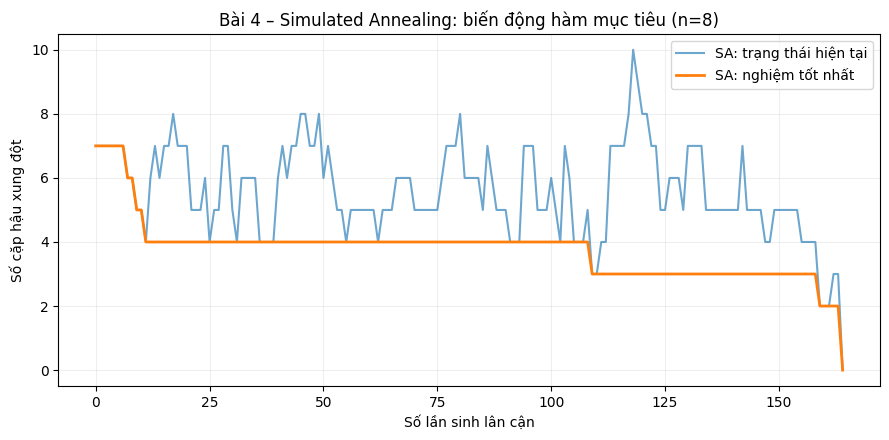

Số bước xấu được chấp nhận: 34


In [23]:
# 4.6. Đồ thị hội tụ: trạng thái hiện tại có thể tệ hơn trong SA,
# nhưng nghiệm tốt nhất đã thấy (best-so-far) không tăng.
# Chọn một seed minh họa bước xấu thực sự được chấp nhận.
example_board=board_8_random.copy()
sa_example=None
for try_seed in [20261015+j for j in range(30)]:
    candidate=simulated_annealing_queens(example_board,seed=try_seed,
                        T0=3.0,alpha=.995,max_iter=MAX_ITER_SA_BAI4)
    if candidate['accepted_worse']>0:
        sa_example=candidate
        break
assert sa_example is not None
fig,ax=plt.subplots(figsize=(9,4.5))
ax.plot(sa_example['history_current'],label='SA: trạng thái hiện tại',alpha=.65)
ax.plot(sa_example['history_best'],label='SA: nghiệm tốt nhất',linewidth=2)
ax.set(xlabel='Số lần sinh lân cận',ylabel='Số cặp hậu xung đột',
       title='Bài 4 – Simulated Annealing: biến động hàm mục tiêu (n=8)')
ax.legend();ax.grid(alpha=.2);fig.tight_layout()
fig.savefig('Bai4_SA_Convergence.png',dpi=160)
plt.show()
print('Số bước xấu được chấp nhận:',sa_example['accepted_worse'])


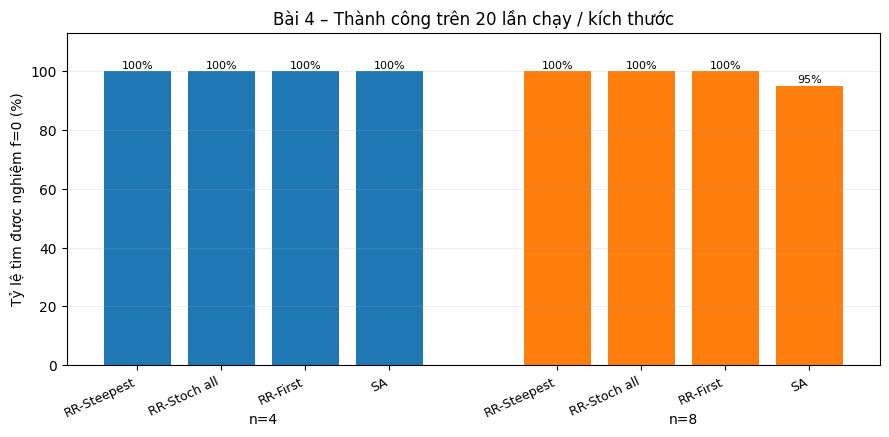

In [24]:
# 4.7. So sánh tỷ lệ thành công giữa RR và SA theo n.
fig,ax=plt.subplots(figsize=(9,4.5))
for i,(n,grp) in enumerate(summary_bai4.groupby('n',sort=True)):
    positions=np.arange(len(grp)) + (i*(len(grp)+1))
    ax.bar(positions,grp['success_rate']*100)
    for x,row in zip(positions,grp.itertuples()):
        ax.text(x,row.success_rate*100+1,f'{100*row.success_rate:.0f}%',
                ha='center',fontsize=8)
    ax.text(positions.mean(),-20,f'n={n}',ha='center')
ax.set_xticks(np.concatenate([np.arange(4),np.arange(5,9)]))
ax.set_xticklabels(['RR-Steepest','RR-Stoch all','RR-First','SA']*2,
                   rotation=25,ha='right',fontsize=9)
ax.set_ylabel('Tỷ lệ tìm được nghiệm f=0 (%)')
ax.set_ylim(0,113);ax.set_title('Bài 4 – Thành công trên 20 lần chạy / kích thước')
ax.grid(axis='y',alpha=.2);fig.tight_layout()
fig.savefig('Bai4_RR_SA_Success_Rates.png',dpi=160)
plt.show()


In [25]:
# 4.8. Xuất CSV bằng đường dẫn tương đối.
df_bai4_demo.to_csv('Bai4_Demo_Results.csv',index=False)
df_bai4_trials.to_csv('Bai4_Trial_Results.csv',index=False)
summary_bai4.to_csv('Bai4_Summary_Results.csv',index=False)
df_sa_grid.to_csv('Bai4_SA_Temperature_Trials.csv',index=False)
summary_sa_grid.to_csv('Bai4_SA_Temperature_Summary.csv',index=False)
print('Đã xuất 5 bảng CSV và 2 hình PNG vào thư mục chạy notebook.')


Đã xuất 5 bảng CSV và 2 hình PNG vào thư mục chạy notebook.


## 4.9. Nhận xét và kết luận Bài 4

Random Restart khắc phục một phần hạn chế của Hill Climbing bằng cách đổi trạng thái khởi tạo sau khi một lượt dừng tại cực tiểu cục bộ. Nghiệm tốt nhất được giữ lại giữa các lần chạy nên `best_f` không tăng theo số lượt restart; đổi lại, chi phí đánh giá `conflicts()` có thể tăng khi cần nhiều lần khởi động lại.

Simulated Annealing thử di chuyển ngẫu nhiên và có thể chấp nhận trạng thái tệ hơn. Cần phân biệt `final_current_f` và `best_f`: trạng thái cuối có thể kém hơn trạng thái tốt nhất từng gặp. Nhiệt độ cao và tốc độ làm nguội chậm thường cho phép chấp nhận bước xấu nhiều hơn, nhưng hiệu quả tìm được `f=0` còn phụ thuộc seed, ngân sách và bài toán.

Các bảng trên dùng đúng cùng seed/bàn cờ đầu cho những thuật toán trong một trial; tuy nhiên Random Restart và SA dùng **ngân sách không đồng nhất** (số lượt khởi động so với số lần sinh lân cận), nên khi so sánh cần xét đồng thời tỷ lệ thành công, số lần gọi hàm mục tiêu và thời gian đo. Dữ liệu thời gian là một tập mẫu trong môi trường chạy hiện tại, không bảo đảm tương tự ở cấu hình máy khác.

Task 6 vẫn để nguyên để thực hiện tại Bài 8 – Tổng hợp thí nghiệm và phân tích, bao gồm thí nghiệm từ 100 seed trở lên và biểu đồ khả năng mở rộng theo n.

## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

In [26]:
# Code

### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

In [27]:
# Code and description go here

### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

In [28]:
# Code and description go here

## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation 

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

In [29]:
# Code and description go here

## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Implement a Genetic Algorithm for the n-Queens problem

In [30]:
# Code and description go here